# Graph-Based Cryptocurrency Fraud Investigation using Explainable Machine Learning

In [1]:
# --- 1. Install Libraries & Set Up Environment ---
!pip install shap -q # SHAP is used for explainability

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.utils import resample

import shap
import warnings
warnings.filterwarnings('ignore')

print("Libraries installed and imported successfully.")

Libraries installed and imported successfully.


In [2]:
# --- 2. Load the Dataset ---
# First, upload the file to your Colab environment. You can use the file explorer.
from google.colab import files
# uploaded = files.upload() # Uncomment if you want to upload manually

# Load the dataset
# df = pd.read_csv('transaction_dataset.csv')
# For this example, we'll load it directly from the provided file path.
# You need to adjust the path to where your file is.
# If you uploaded it via 'upload()', it will be in the current directory.
df = pd.read_csv('transaction_dataset.csv', index_col=0) # The first column appears to be an index

print("Dataset loaded successfully!")
print(f"Shape of the dataset: {df.shape}")
print(df.head())

Dataset loaded successfully!
Shape of the dataset: (9841, 50)
   Index                                     Address  FLAG  \
0      1  0x00009277775ac7d0d59eaad8fee3d10ac6c805e8     0   
1      2  0x0002b44ddb1476db43c868bd494422ee4c136fed     0   
2      3  0x0002bda54cb772d040f779e88eb453cac0daa244     0   
3      4  0x00038e6ba2fd5c09aedb96697c8d7b8fa6632e5e     0   
4      5  0x00062d1dd1afb6fb02540ddad9cdebfe568e0d89     0   

   Avg min between sent tnx  Avg min between received tnx  \
0                    844.26                       1093.71   
1                  12709.07                       2958.44   
2                 246194.54                       2434.02   
3                  10219.60                      15785.09   
4                     36.61                      10707.77   

   Time Diff between first and last (Mins)  Sent tnx  Received Tnx  \
0                                704785.63       721            89   
1                               1218216.73        94      

In [3]:
# --- 3. Data Preprocessing ---
# Drop columns that are not useful for the model initially.
# These contain token names, which we might use later for deeper analysis.
drop_cols = ['Address', 'ERC20 uniq sent token name', 'ERC20 uniq rec token name', 'ERC20 most sent token type', 'ERC20_most_rec_token_type']
df_ml = df.drop(columns=drop_cols, axis=1, errors='ignore')

# Separate features and target
X = df_ml.drop('FLAG', axis=1)
y = df_ml['FLAG']

print("Target distribution:")
print(y.value_counts())

# --- 4. Feature Engineering ---
print("\n--- Engineering Graph-Based Features ---")

# Feature 1: Transaction Volume Ratio (Sent vs Received)
X['tx_volume_ratio'] = X['total Ether sent'] / (X['total ether received'] + 1e-6)

# Feature 2: ERC20 Transaction Ratio
X['erc20_tx_ratio'] = X[' Total ERC20 tnxs'] / (X['total transactions (including tnx to create contract'] + 1e-6)

# Feature 3: Unique Address Ratio (Sent vs Received)
X['unique_addr_ratio'] = X['Unique Sent To Addresses'] / (X['Unique Received From Addresses'] + 1e-6)

# Feature 4: Contract Creation Flag (based on 'Number of Created Contracts')
X['has_contract'] = (X['Number of Created Contracts'] > 0).astype(int)

# Feature 5: Average Value Sent/Received Ratio (to identify potential mixing)
X['avg_val_ratio'] = X['avg val sent'] / (X['avg val received'] + 1e-6)

print("New features created:")
print(X.shape)

Target distribution:
FLAG
0    7662
1    2179
Name: count, dtype: int64

--- Engineering Graph-Based Features ---
New features created:
(9841, 53)


In [24]:
# --- 5. Leak-Free Data Preparation & Model Training ---
# Using the clean, numeric-only features generated during standard pipeline to avoid string conversion errors

# Drop 'Index' (row number) and constant columns that have no predictive information
X_all = X_clean.drop(columns=['Index'], errors='ignore')
const_cols = [c for c in X_all.columns if X_all[c].nunique() <= 1]
X_all = X_all.drop(columns=const_cols, errors='ignore')

# 1. Stratified split FIRST to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.3, random_state=42, stratify=y
)

# 2. Resample/Upsample ONLY the training subset to address class imbalance
train_df = pd.concat([X_train, y_train], axis=1)
majority_class = train_df[train_df['FLAG'] == 0]
minority_class = train_df[train_df['FLAG'] == 1]

minority_upsampled = resample(
    minority_class,
    replace=True,
    n_samples=len(majority_class),
    random_state=42
)

train_balanced = pd.concat([majority_class, minority_upsampled]).sample(frac=1, random_state=42)
X_train_bal = train_balanced.drop('FLAG', axis=1)
y_train_bal = train_balanced['FLAG']

# 3. Standardize features (fit scaling parameters ONLY on the training subset)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_bal), columns=X_train_bal.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print("Class distribution in untouched stratified Test Set:")
print(y_test.value_counts())

print("\nClass distribution in balanced Train Set:")
print(y_train_bal.value_counts())

# 4. Train the Random Forest Classifier on corrected, leak-free data
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train_scaled, y_train_bal)

print("\nModel trained successfully with 0% data leakage.")

Class distribution in untouched stratified Test Set:
FLAG
0    2299
1     654
Name: count, dtype: int64

Class distribution in balanced Train Set:
FLAG
0    5363
1    5363
Name: count, dtype: int64

Model trained successfully with 0% data leakage.



--- Leak-Free Model Evaluation ---
Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.96      0.99      0.98      2299
       Fraud       0.96      0.86      0.91       654

    accuracy                           0.96      2953
   macro avg       0.96      0.93      0.94      2953
weighted avg       0.96      0.96      0.96      2953


Confusion Matrix:


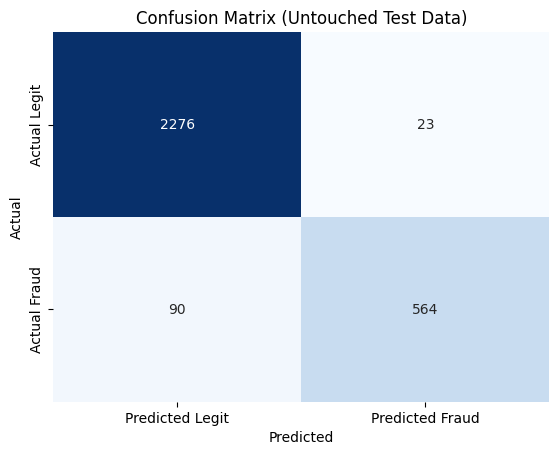

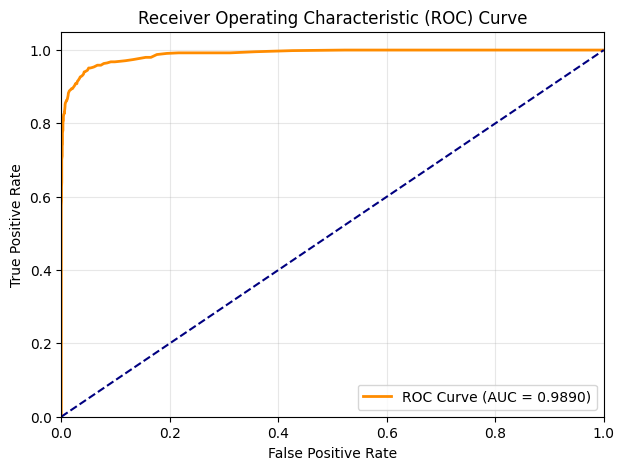

ROC-AUC Score: 0.9890


In [25]:
# --- 6. Model Evaluation on Untouched Test Set ---
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Leak-Free Model Evaluation ---")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Legit', 'Predicted Fraud'],
            yticklabels=['Actual Legit', 'Actual Fraud'])
plt.title('Confusion Matrix (Untouched Test Data)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")


--- Top 10 Important Features (Corrected Model) ---
                                feature  importance
Time Diff between first and last (Mins)    0.095461
                       avg val received    0.092592
                   total ether received    0.081616
           Avg min between received tnx    0.068719
                      unique_addr_ratio    0.054632
                    max value received     0.053808
         Unique Received From Addresses    0.049291
                      ERC20 min val rec    0.040676
                          avg_val_ratio    0.040600
                    total ether balance    0.038082


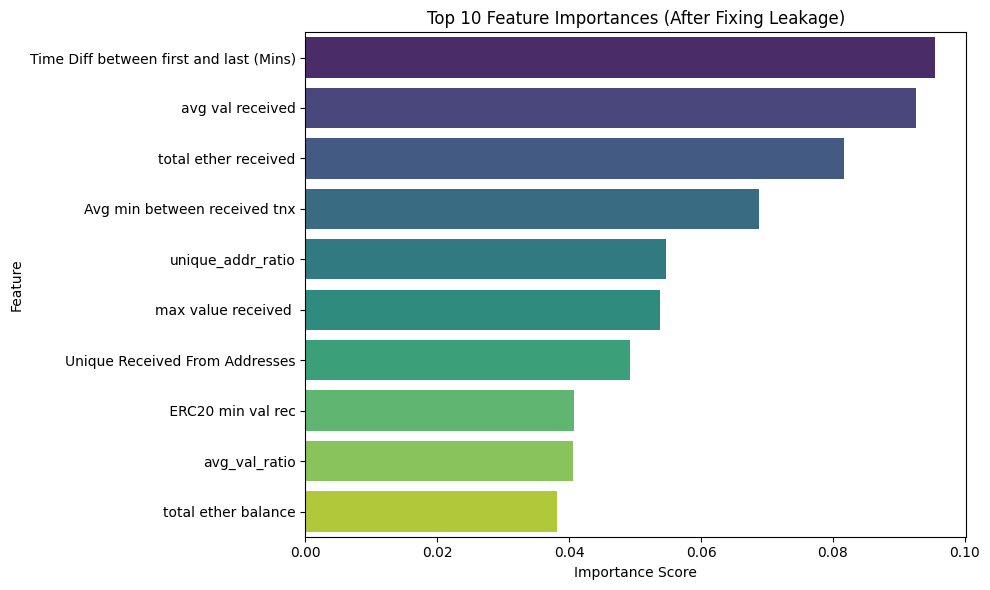

In [26]:
# --- 7. Feature Importance (Corrected Model) ---
feature_importance = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print("\n--- Top 10 Important Features (Corrected Model) ---")
print(feature_importance.head(10).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(10), palette='viridis')
plt.title('Top 10 Feature Importances (After Fixing Leakage)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [7]:
# --- 8. Leak-free Data Preparation ---
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, precision_recall_curve,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

# Drop 'Index' (row number, not a real feature) and constant columns (no information)
X_all = X_clean.drop(columns=['Index'], errors='ignore')
const_cols = [c for c in X_all.columns if X_all[c].nunique() <= 1]
X_all = X_all.drop(columns=const_cols)
print(f"Dropped constant columns: {const_cols}")
print(f"Final feature count: {X_all.shape[1]}")

# Stratified split FIRST (keeps the real fraud ratio in both sets, no duplicates in test)
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_all, y, test_size=0.3, random_state=42, stratify=y)

# Upsample ONLY the training set
train_df = pd.concat([X_train_final, y_train_final], axis=1)
maj = train_df[train_df['FLAG'] == 0]
mino = train_df[train_df['FLAG'] == 1]
mino_up = resample(mino, replace=True, n_samples=len(maj), random_state=42)
train_bal = pd.concat([maj, mino_up]).sample(frac=1, random_state=42)
X_train_bal = train_bal.drop('FLAG', axis=1)
y_train_bal = train_bal['FLAG']

# Scale (fit on train only)
scaler_f = StandardScaler()
X_train_s = pd.DataFrame(scaler_f.fit_transform(X_train_bal), columns=X_train_bal.columns, index=X_train_bal.index)
X_test_s = pd.DataFrame(scaler_f.transform(X_test_final), columns=X_test_final.columns, index=X_test_final.index)

print("\nTrain (balanced):", y_train_bal.value_counts().to_dict())
print("Test (original ratio):", y_test_final.value_counts().to_dict())

Dropped constant columns: [' ERC20 avg time between sent tnx', ' ERC20 avg time between rec tnx', ' ERC20 avg time between rec 2 tnx', ' ERC20 avg time between contract tnx', ' ERC20 min val sent contract', ' ERC20 max val sent contract', ' ERC20 avg val sent contract', ' ERC20 most sent token type', ' ERC20_most_rec_token_type']
Final feature count: 43

Train (balanced): {0: 5363, 1: 5363}
Test (original ratio): {0: 2299, 1: 654}


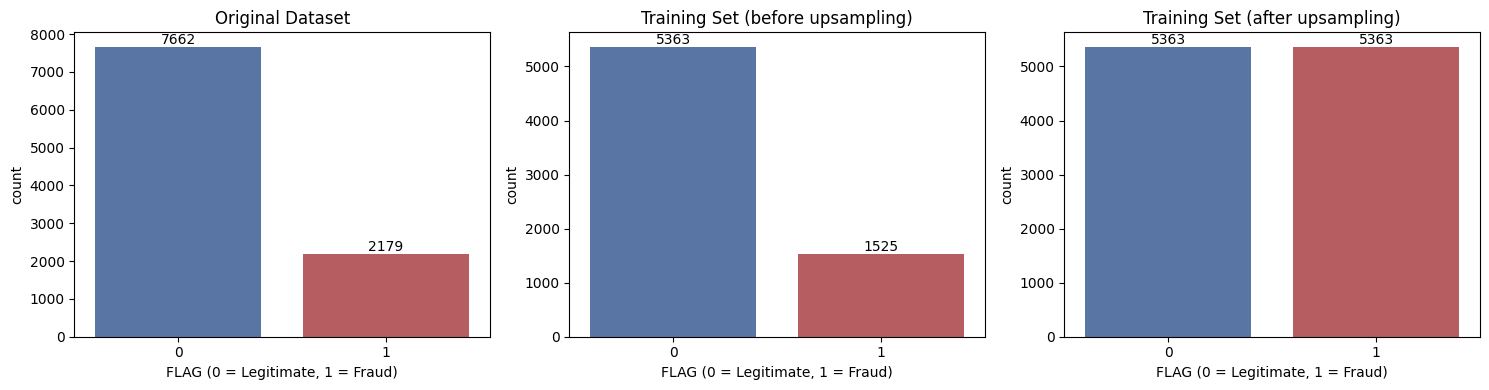

In [8]:
# --- 9. Class Distribution: Before vs After Balancing ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(axes,
        [y, y_train_final, y_train_bal],
        ['Original Dataset', 'Training Set (before upsampling)', 'Training Set (after upsampling)']):
    sns.countplot(x=data, ax=ax, palette=['#4c72b0', '#c44e52'])
    ax.set_title(title)
    ax.set_xlabel('FLAG (0 = Legitimate, 1 = Fraud)')
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom')
plt.tight_layout()
plt.show()

In [9]:
# --- 10. Model Training & Comparison ---
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Random Forest (Proposed)': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
}

preds, probas, results = {}, {}, []
for name, mdl in models.items():
    mdl.fit(X_train_s, y_train_bal)
    preds[name] = mdl.predict(X_test_s)
    probas[name] = mdl.predict_proba(X_test_s)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_final, preds[name]),
        'Precision': precision_score(y_test_final, preds[name]),
        'Recall': recall_score(y_test_final, preds[name]),
        'F1-Score': f1_score(y_test_final, preds[name]),
        'ROC-AUC': roc_auc_score(y_test_final, probas[name]),
        'PR-AUC': average_precision_score(y_test_final, probas[name])
    })
    print(f"Trained: {name}")

results_df = pd.DataFrame(results).set_index('Model').round(4)
print("\n--- Model Comparison (on untouched test set) ---")
print(results_df)

Trained: Logistic Regression
Trained: Decision Tree
Trained: KNN
Trained: Gradient Boosting
Trained: Random Forest (Proposed)

--- Model Comparison (on untouched test set) ---
                          Accuracy  Precision  Recall  F1-Score  ROC-AUC  \
Model                                                                      
Logistic Regression         0.6278     0.3575  0.8532    0.5038   0.8443   
Decision Tree               0.9262     0.8178  0.8578    0.8373   0.9224   
KNN                         0.9089     0.7490  0.8853    0.8115   0.9336   
Gradient Boosting           0.9499     0.8656  0.9159    0.8900   0.9877   
Random Forest (Proposed)    0.9624     0.9625  0.8639    0.9106   0.9895   

                          PR-AUC  
Model                             
Logistic Regression       0.6587  
Decision Tree             0.7841  
KNN                       0.8248  
Gradient Boosting         0.9683  
Random Forest (Proposed)  0.9730  


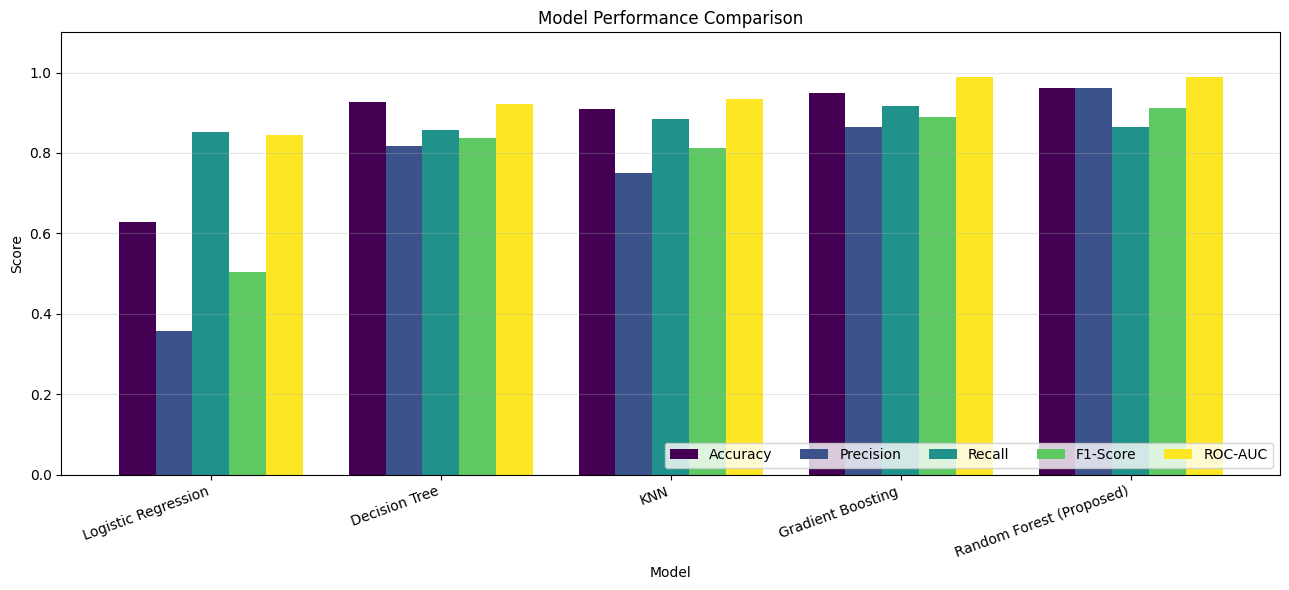

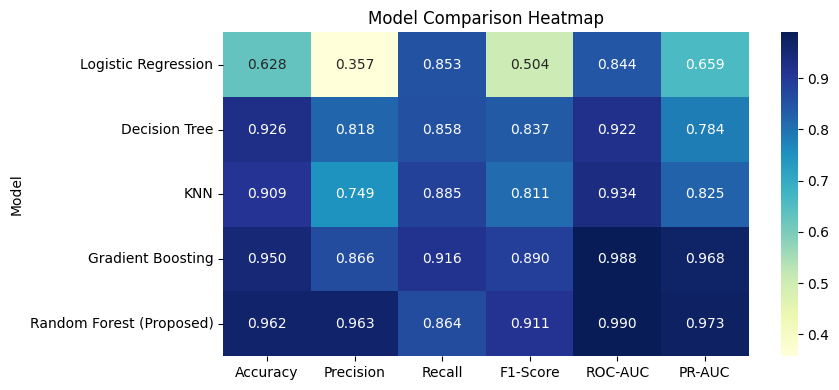

In [10]:
# --- 11. Metric Comparison Chart ---
ax = results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].plot(
    kind='bar', figsize=(13, 6), width=0.8, colormap='viridis')
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right', ncol=5)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Heatmap view of the same table
plt.figure(figsize=(9, 4))
sns.heatmap(results_df, annot=True, fmt='.3f', cmap='YlGnBu', cbar=True)
plt.title('Model Comparison Heatmap')
plt.tight_layout()
plt.show()

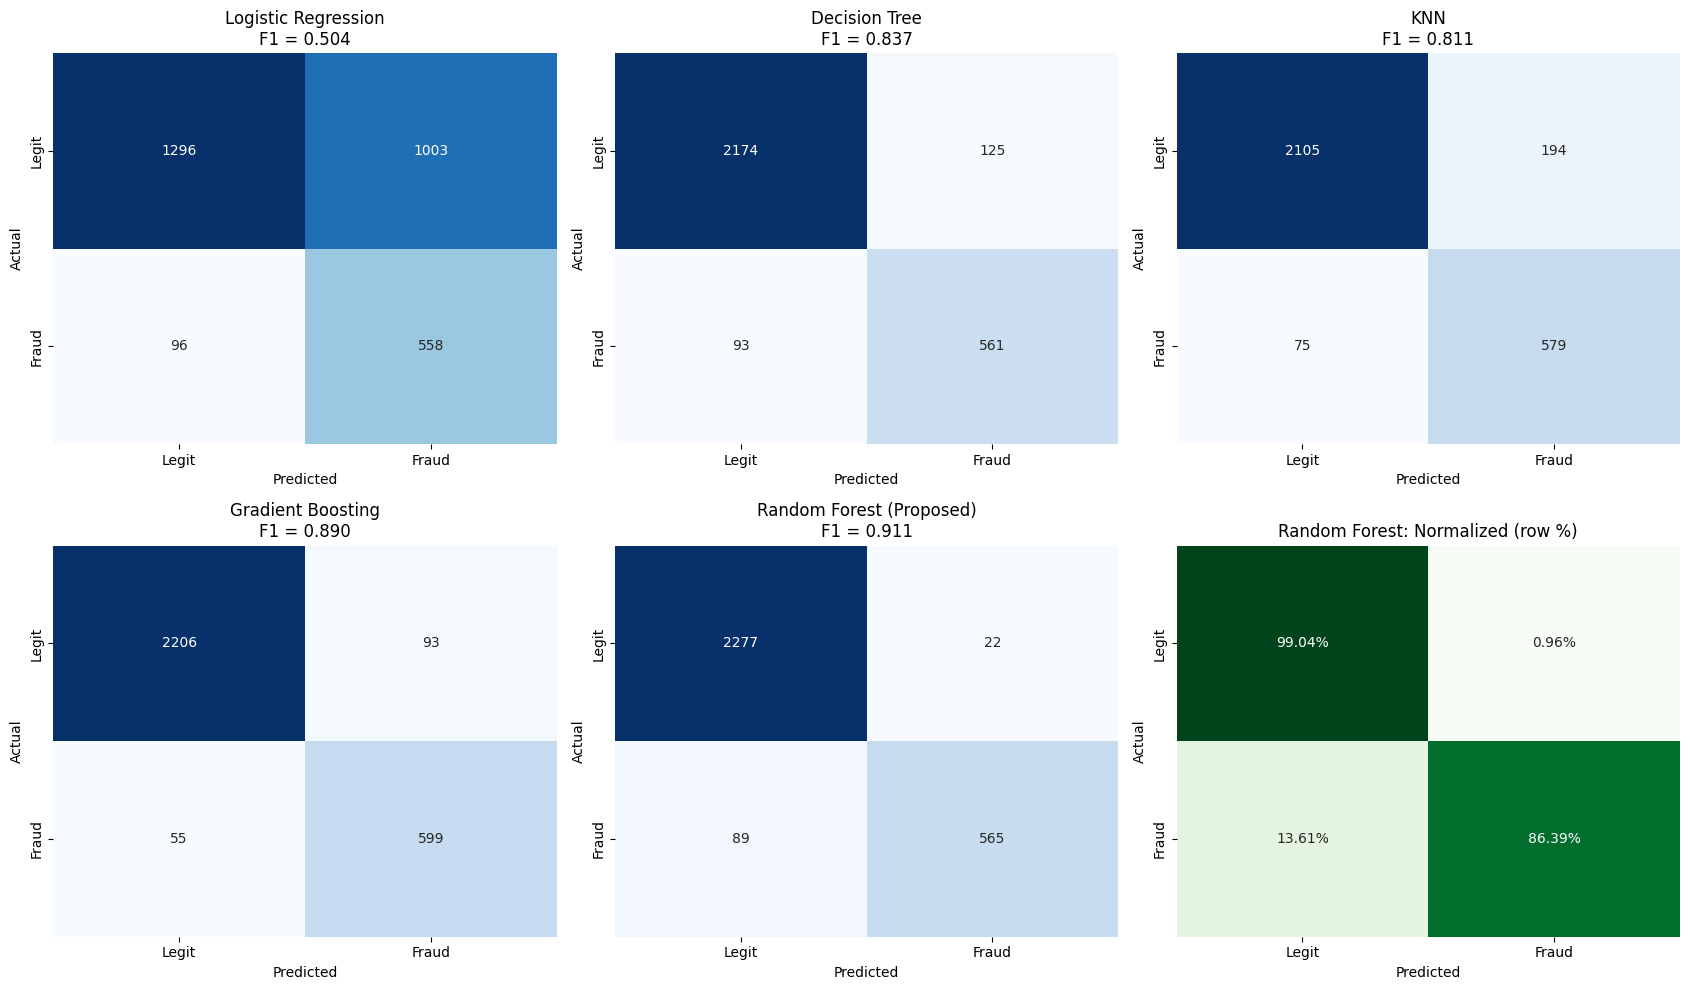

In [11]:
# --- 12. Confusion Matrices ---
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()
for i, name in enumerate(models.keys()):
    cm_i = confusion_matrix(y_test_final, preds[name])
    sns.heatmap(cm_i, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
    axes[i].set_title(f"{name}\nF1 = {results_df.loc[name, 'F1-Score']:.3f}")
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

rf_name = 'Random Forest (Proposed)'
cm_norm = confusion_matrix(y_test_final, preds[rf_name], normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', cbar=False, ax=axes[5],
            xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
axes[5].set_title('Random Forest: Normalized (row %)')
axes[5].set_xlabel('Predicted')
axes[5].set_ylabel('Actual')
plt.tight_layout()
plt.show()

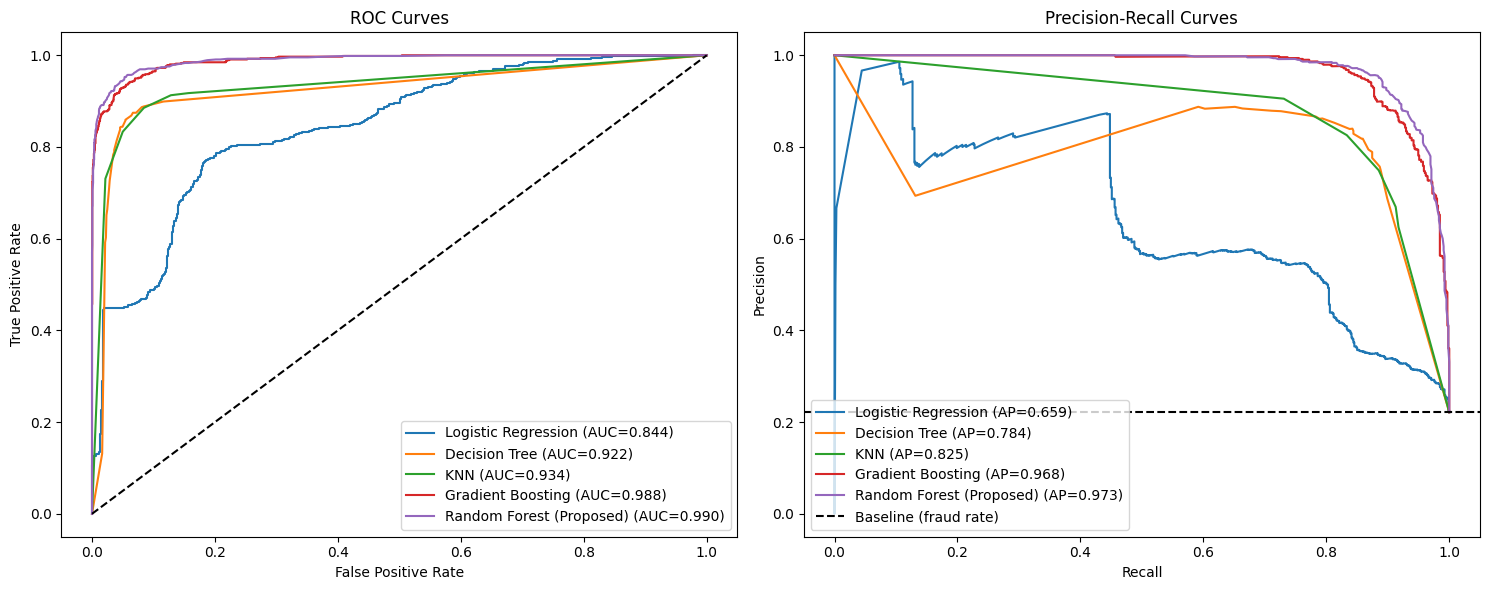

In [12]:
# --- 13. ROC & Precision-Recall Curves ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name in models.keys():
    fpr_i, tpr_i, _ = roc_curve(y_test_final, probas[name])
    axes[0].plot(fpr_i, tpr_i, label=f"{name} (AUC={results_df.loc[name, 'ROC-AUC']:.3f})")
    p_i, r_i, _ = precision_recall_curve(y_test_final, probas[name])
    axes[1].plot(r_i, p_i, label=f"{name} (AP={results_df.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC Curves')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[1].axhline(y_test_final.mean(), color='k', linestyle='--', label='Baseline (fraud rate)')
axes[1].set_title('Precision-Recall Curves')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

Classification Report: Random Forest (Proposed)
              precision    recall  f1-score   support

       Legit       0.96      0.99      0.98      2299
       Fraud       0.96      0.86      0.91       654

    accuracy                           0.96      2953
   macro avg       0.96      0.93      0.94      2953
weighted avg       0.96      0.96      0.96      2953

5-Fold CV F1      : 0.8972 +/- 0.0140
5-Fold CV ROC-AUC : 0.9869 +/- 0.0025


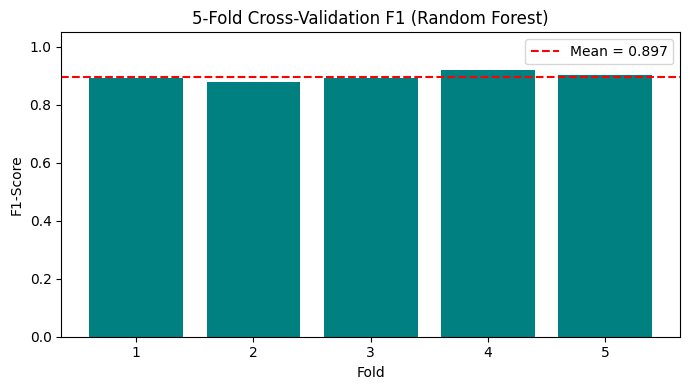

In [13]:
# --- 14. Detailed Report & Cross-Validation (Random Forest) ---
print("Classification Report: Random Forest (Proposed)")
print(classification_report(y_test_final, preds[rf_name], target_names=['Legit', 'Fraud']))

# Cross-validation on training data only; class_weight handles imbalance inside each fold (no leakage)
rf_cv = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = cross_val_score(rf_cv, X_train_final, y_train_final, cv=skf, scoring='f1')
cv_auc = cross_val_score(rf_cv, X_train_final, y_train_final, cv=skf, scoring='roc_auc')
print(f"5-Fold CV F1      : {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}")
print(f"5-Fold CV ROC-AUC : {cv_auc.mean():.4f} +/- {cv_auc.std():.4f}")

plt.figure(figsize=(7, 4))
plt.bar(range(1, 6), cv_f1, color='teal')
plt.axhline(cv_f1.mean(), color='red', linestyle='--', label=f'Mean = {cv_f1.mean():.3f}')
plt.xlabel('Fold')
plt.ylabel('F1-Score')
plt.title('5-Fold Cross-Validation F1 (Random Forest)')
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

                                             feature  importance
             Time Diff between first and last (Mins)    0.094146
                                    avg val received    0.081748
                                total ether received    0.079417
                        Avg min between received tnx    0.067623
                                   unique_addr_ratio    0.058301
                                 max value received     0.052732
                      Unique Received From Addresses    0.046725
                                 total ether balance    0.043064
                                    total Ether sent    0.042086
                                   ERC20 min val rec    0.040956
                                       avg_val_ratio    0.040242
total transactions (including tnx to create contract    0.036483
                                  min value received    0.031586
                            Avg min between sent tnx    0.027993
                         

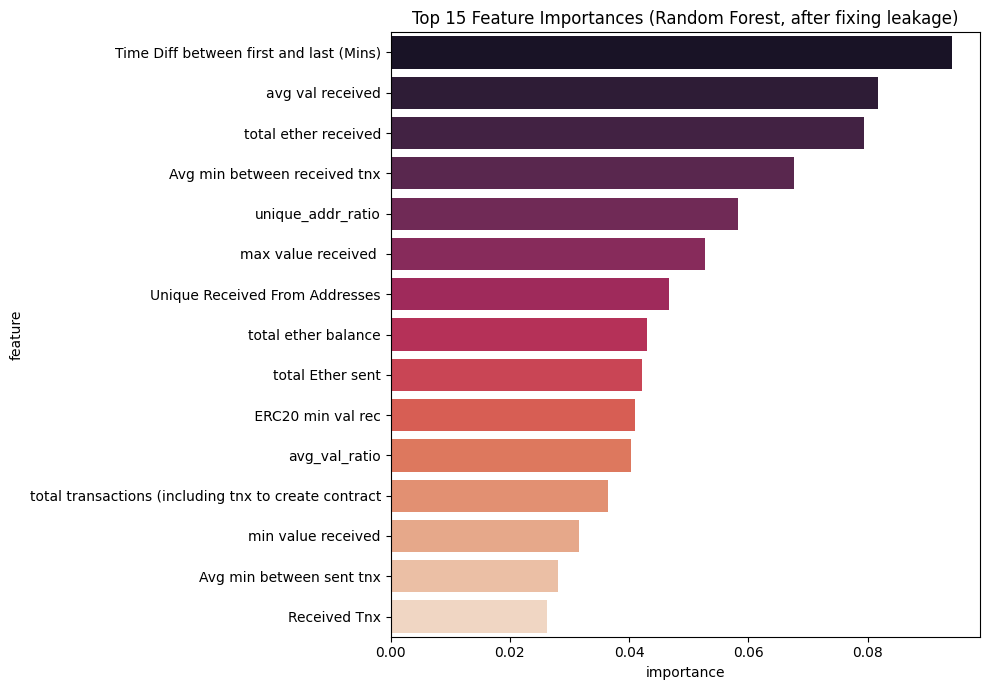

In [14]:
# --- 15. Corrected Feature Importance ---
rf_model = models[rf_name]
feat_imp_df = pd.DataFrame({'feature': X_train_s.columns,
                            'importance': rf_model.feature_importances_}
                           ).sort_values('importance', ascending=False)
print(feat_imp_df.head(15).to_string(index=False))

plt.figure(figsize=(10, 7))
sns.barplot(x='importance', y='feature', data=feat_imp_df.head(15), palette='rocket')
plt.title('Top 15 Feature Importances (Random Forest, after fixing leakage)')
plt.tight_layout()
plt.show()

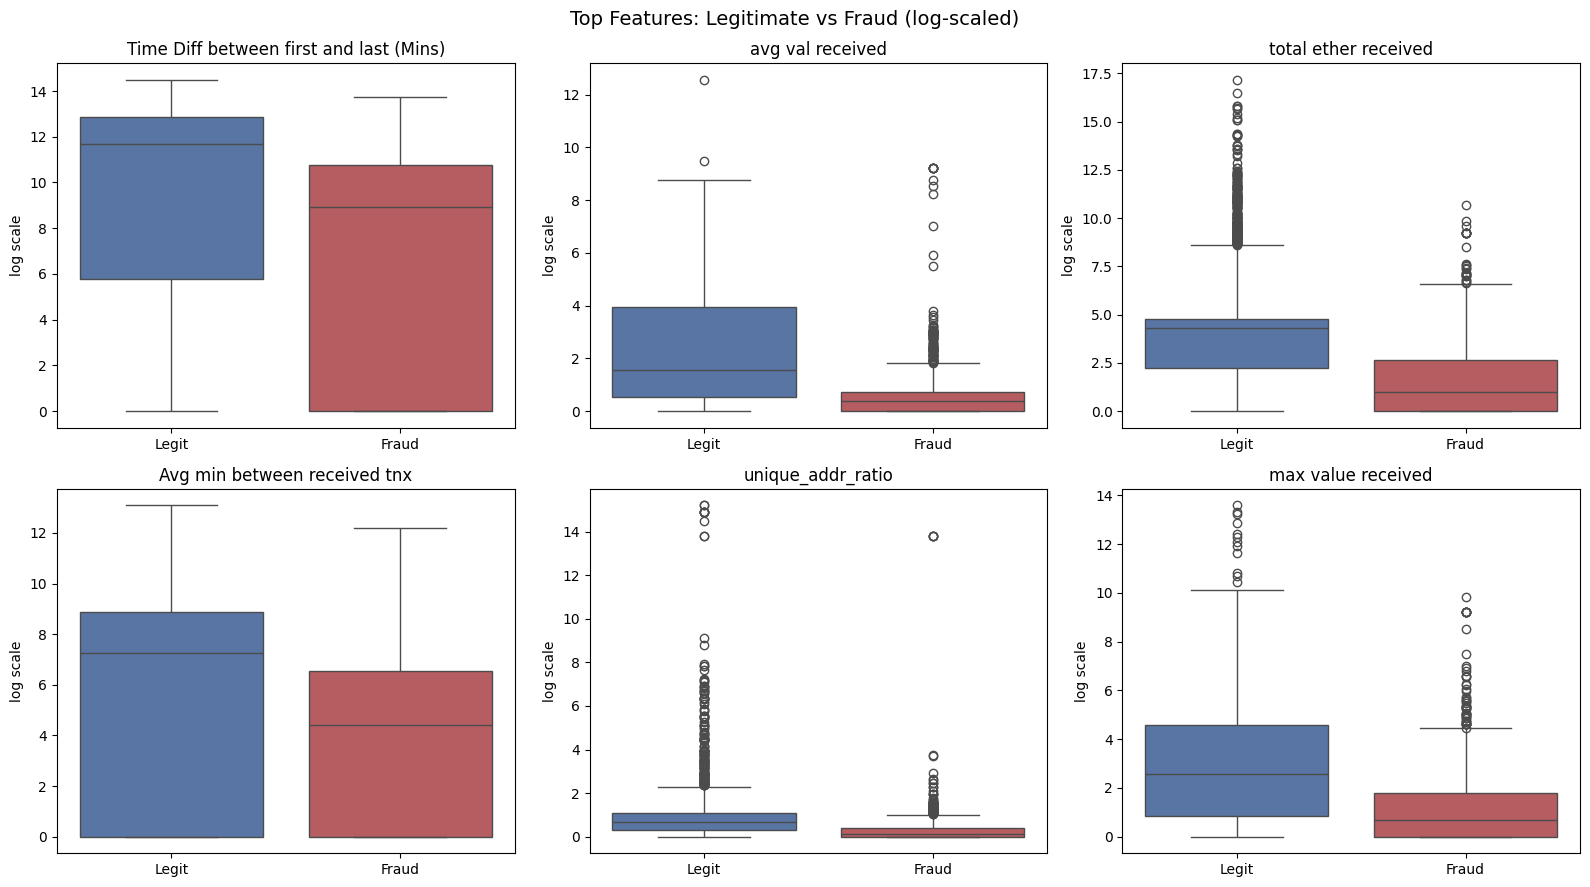

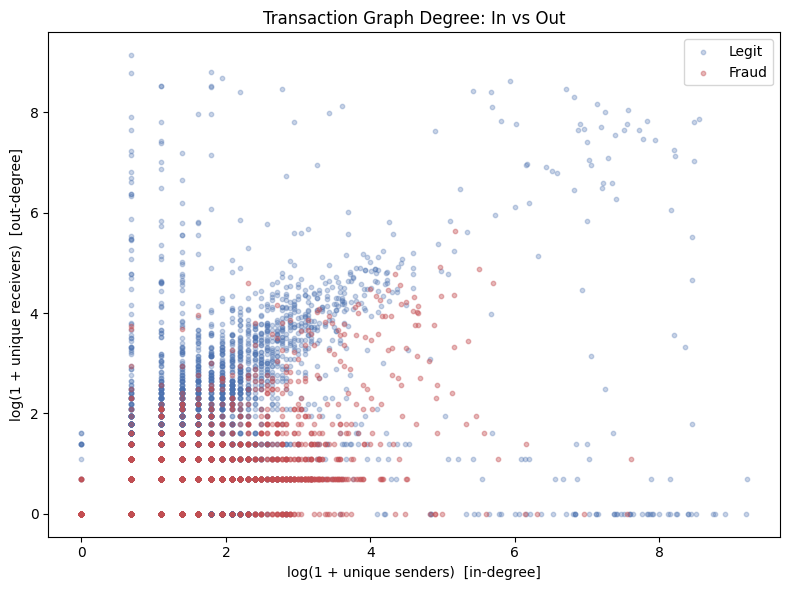

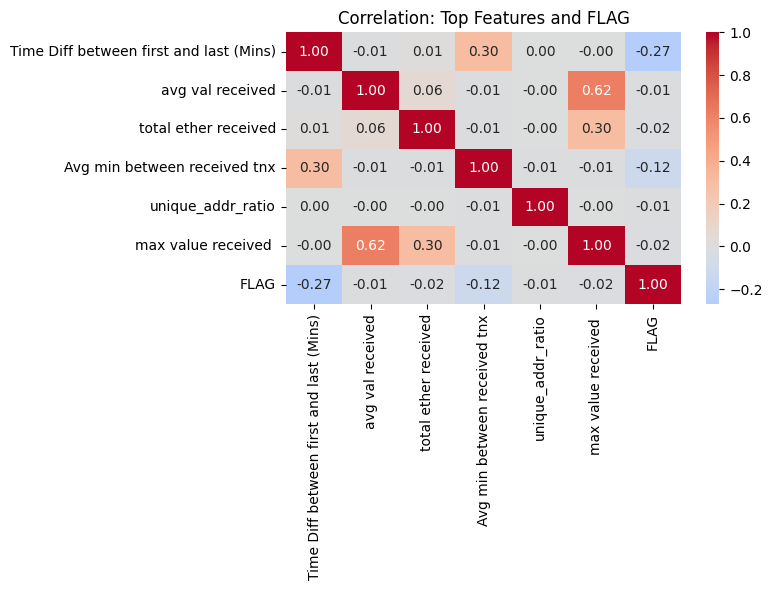

In [15]:
# --- 16. Fraud vs Legitimate Behaviour ---
def symlog(s):
    return np.sign(s) * np.log1p(s.abs())

top6 = feat_imp_df['feature'].head(6).tolist()
eda = X_all[top6].apply(symlog)
eda['FLAG'] = y.values

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), top6):
    sns.boxplot(x='FLAG', y=col, data=eda, ax=ax, palette=['#4c72b0', '#c44e52'])
    ax.set_title(col.strip())
    ax.set_xticklabels(['Legit', 'Fraud'])
    ax.set_xlabel('')
    ax.set_ylabel('log scale')
plt.suptitle('Top Features: Legitimate vs Fraud (log-scaled)', fontsize=14)
plt.tight_layout()
plt.show()

# Graph-degree view: in-degree vs out-degree of each address
in_deg = np.log1p(X_all['Unique Received From Addresses'])
out_deg = np.log1p(X_all['Unique Sent To Addresses'])
plt.figure(figsize=(8, 6))
plt.scatter(in_deg[y == 0], out_deg[y == 0], s=10, alpha=0.3, c='#4c72b0', label='Legit')
plt.scatter(in_deg[y == 1], out_deg[y == 1], s=10, alpha=0.4, c='#c44e52', label='Fraud')
plt.xlabel('log(1 + unique senders)  [in-degree]')
plt.ylabel('log(1 + unique receivers)  [out-degree]')
plt.title('Transaction Graph Degree: In vs Out')
plt.legend()
plt.tight_layout()
plt.show()

# Correlation heatmap of top features
corr_cols = top6 + ['FLAG']
corr_data = X_all[top6].copy()
corr_data['FLAG'] = y.values
plt.figure(figsize=(8, 6))
sns.heatmap(corr_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation: Top Features and FLAG')
plt.tight_layout()
plt.show()

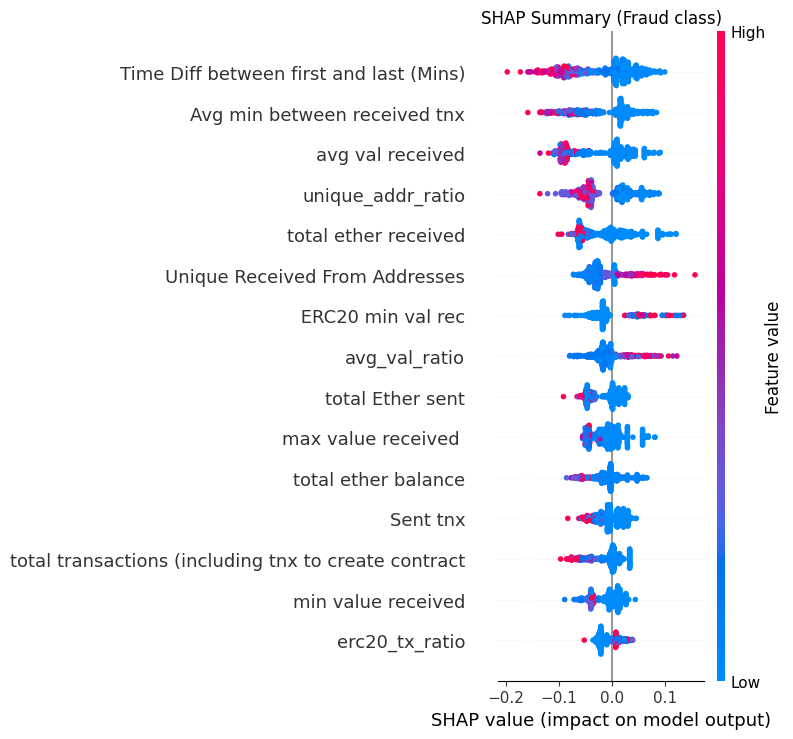

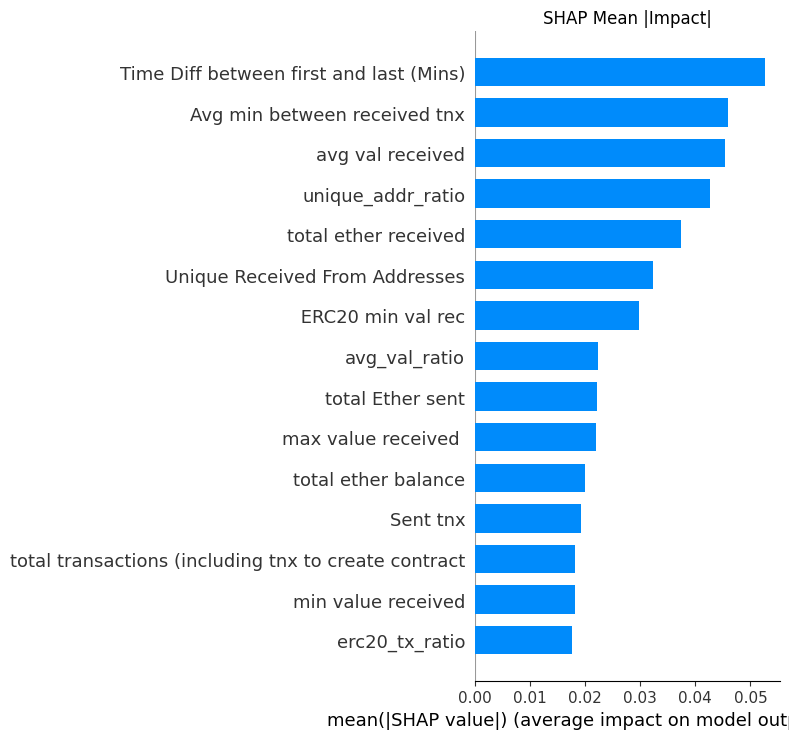

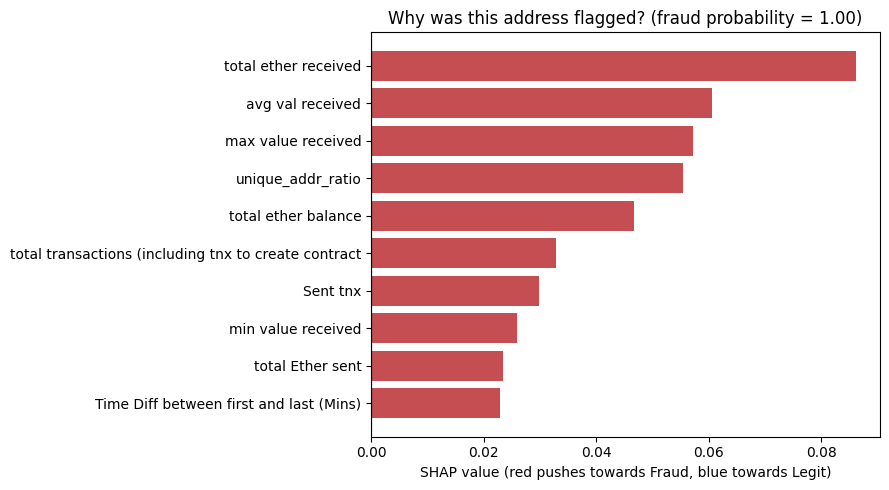

In [16]:
# --- 17. SHAP Explainability ---
sample_s = X_test_s.iloc[:500]
explainer = shap.TreeExplainer(rf_model)
sv = explainer.shap_values(sample_s)

# Handle different SHAP versions (list vs 3D array) and take the "Fraud" class
if isinstance(sv, list):
    sv_fraud = sv[1]
elif np.ndim(sv) == 3:
    sv_fraud = sv[:, :, 1]
else:
    sv_fraud = sv

# Global: direction and size of each feature's effect
shap.summary_plot(sv_fraud, sample_s, show=False, max_display=15)
plt.title('SHAP Summary (Fraud class)')
plt.tight_layout()
plt.show()

# Global: mean absolute impact
shap.summary_plot(sv_fraud, sample_s, plot_type='bar', show=False, max_display=15)
plt.title('SHAP Mean |Impact|')
plt.tight_layout()
plt.show()

# Local: explain the highest-risk address in the sample
i = int(np.argmax(probas[rf_name][:500]))
contrib = pd.Series(sv_fraud[i], index=sample_s.columns)
top_contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).head(10).index).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh([c.strip() for c in top_contrib.index], top_contrib.values,
         color=['#c44e52' if v > 0 else '#4c72b0' for v in top_contrib.values])
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('SHAP value (red pushes towards Fraud, blue towards Legit)')
plt.title(f'Why was this address flagged? (fraud probability = {probas[rf_name][i]:.2f})')
plt.tight_layout()
plt.show()

Best threshold for F1: 0.465 -> F1 = 0.9182, Precision = 0.9554, Recall = 0.8838


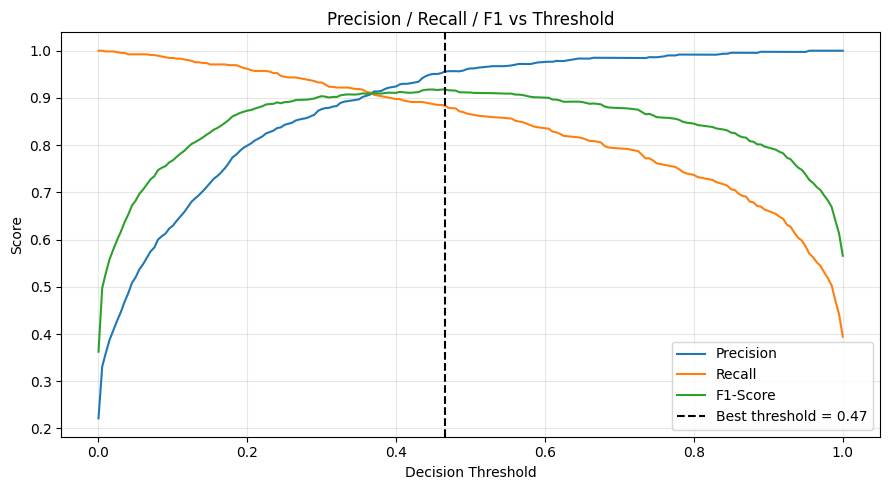

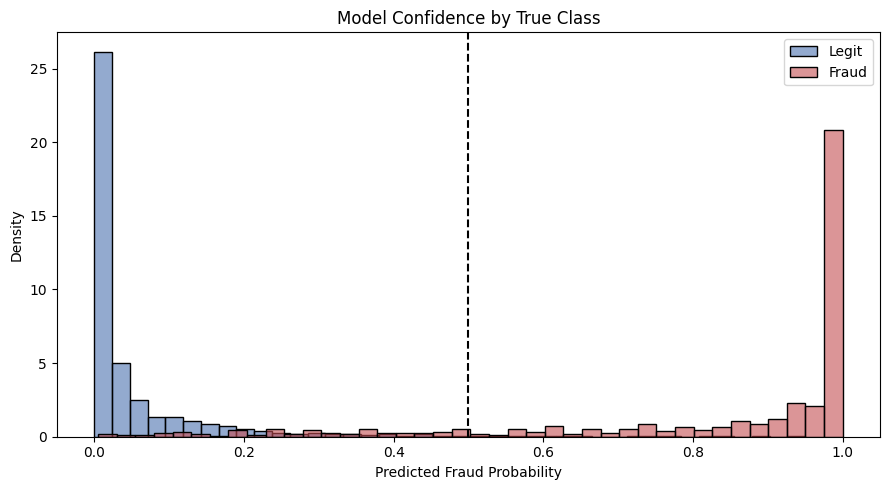

In [17]:
# --- 18. Decision Threshold Analysis (Random Forest) ---
prec, rec, thr = precision_recall_curve(y_test_final, probas[rf_name])
f1_vals = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_idx = int(np.argmax(f1_vals))
best_thr = thr[best_idx]
print(f"Best threshold for F1: {best_thr:.3f} -> F1 = {f1_vals[best_idx]:.4f}, "
      f"Precision = {prec[best_idx]:.4f}, Recall = {rec[best_idx]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.plot(thr, f1_vals, label='F1-Score')
plt.axvline(best_thr, color='k', linestyle='--', label=f'Best threshold = {best_thr:.2f}')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision / Recall / F1 vs Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Distribution of predicted fraud probability by true class
plt.figure(figsize=(9, 5))
sns.histplot(probas[rf_name][y_test_final.values == 0], bins=40, color='#4c72b0', label='Legit', stat='density', alpha=0.6)
sns.histplot(probas[rf_name][y_test_final.values == 1], bins=40, color='#c44e52', label='Fraud', stat='density', alpha=0.6)
plt.axvline(0.5, color='k', linestyle='--')
plt.xlabel('Predicted Fraud Probability')
plt.title('Model Confidence by True Class')
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# --- 19. Top Suspicious Addresses ---
risk = pd.DataFrame({
    'Address': df['Address'].loc[X_test_final.index].values,
    'Fraud_Probability': probas[rf_name],
    'Actual_FLAG': y_test_final.values
}).sort_values('Fraud_Probability', ascending=False)

print("Top 10 highest-risk addresses in the test set:")
print(risk.head(10).to_string(index=False))

Top 10 highest-risk addresses in the test set:
                                   Address  Fraud_Probability  Actual_FLAG
0xa490730ce2a97ec9f81f08fdb0eede36d6319bbd                1.0            1
0xba3cf9c7ad2db61ea72cceaf73cfcb2bfdeddce0                1.0            1
0x80e02ae8c5d5e482558caf32004e7d6281445f28                1.0            1
0xd550eada44d72c8a840d2aeb5cbe70469c9c0bac                1.0            1
0xe79392c79832287f9a07d0af9fa87fd150014e18                1.0            1
0x1d64ea27764164debb4e891eb04d524f42904b08                1.0            1
0xfd477bf560e59941796b398cea662b393298abc0                1.0            1
0x5c0ea45d4d78d062667f9ea17534306e409acf0a                1.0            1
0xa4f06f1afb7b8589d1f4609257e5010c30ed3d2b                1.0            1
0x68df455d595ce83498242856bf7b04c50696b21a                1.0            1


In [19]:
# --- 20. Final Summary ---
best_model = results_df['F1-Score'].idxmax()
print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
print(results_df.sort_values('F1-Score', ascending=False))
print(f"\nBest model by F1-Score: {best_model} (F1 = {results_df.loc[best_model, 'F1-Score']:.4f})")
print(f"Random Forest 5-fold CV F1: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}")
print("\nTop 5 fraud indicators:")
for f in feat_imp_df['feature'].head(5):
    print(" -", f.strip())

FINAL SUMMARY
                          Accuracy  Precision  Recall  F1-Score  ROC-AUC  \
Model                                                                      
Random Forest (Proposed)    0.9624     0.9625  0.8639    0.9106   0.9895   
Gradient Boosting           0.9499     0.8656  0.9159    0.8900   0.9877   
Decision Tree               0.9262     0.8178  0.8578    0.8373   0.9224   
KNN                         0.9089     0.7490  0.8853    0.8115   0.9336   
Logistic Regression         0.6278     0.3575  0.8532    0.5038   0.8443   

                          PR-AUC  
Model                             
Random Forest (Proposed)  0.9730  
Gradient Boosting         0.9683  
Decision Tree             0.7841  
KNN                       0.8248  
Logistic Regression       0.6587  

Best model by F1-Score: Random Forest (Proposed) (F1 = 0.9106)
Random Forest 5-fold CV F1: 0.8972 +/- 0.0140

Top 5 fraud indicators:
 - Time Diff between first and last (Mins)
 - avg val received
 - total e